<a href="https://colab.research.google.com/github/hariharan-s-2005/HCL/blob/main/UNIT_3%20/English_to_Spanish_Transformer_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q datasets tensorflow nltk sacrebleu

In [3]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Deep learning
import tensorflow as tf

# Text processing
import re
import time

# Dataset loading
from datasets import load_dataset

# Transformer components
from tensorflow.keras.layers import (
    Input,
    Dense,
    Embedding,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    Layer
)

# Model creation
from tensorflow.keras.models import Model

from tensorflow.keras.layers import Layer
# Tokenization and padding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Evaluation
import sacrebleu

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

All libraries imported successfully!
TensorFlow version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:


from datasets import load_dataset

dataset = load_dataset(
    "Helsinki-NLP/opus-100",
    "en-es"
)

print(dataset)

# Display dataset sizes
print("\nTraining samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Testing samples:", len(dataset["test"]))

README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

en-es/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237kB            

en-es/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 99.6MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-es/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  238kB            

en-es/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1000000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['translation'],
        num_rows: 1000000
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
})

Training samples: 1000000
Validation samples: 2000
Testing samples: 2000


In [5]:
print("\nFirst 5 Records:")

for i in range(5):
    print(dataset["train"][i]["translation"])


First 5 Records:
{'en': "It was the asbestos in here, that's what did it!", 'es': 'Fueron los asbestos aquí. ¡Eso es lo que ocurrió!'}
{'en': "I'm out of here.", 'es': 'Me voy de aquí.'}
{'en': 'One time, I swear I pooped out a stick of chalk.', 'es': 'Una vez, juro que cagué una barra de tiza.'}
{'en': 'And I will move, do you understand me?', 'es': 'Y prefiero mudarme, ¿Entiendes?'}
{'en': '- Thank you, my lord.', 'es': '- Gracias.'}


In [6]:


import pandas as pd

data = []

for row in dataset["train"]:
    data.append({
        "English": row["translation"]["en"],
        "Spanish": row["translation"]["es"]
    })

df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

Dataset Shape: (1000000, 2)

First 5 Records:
                                            English  \
0  It was the asbestos in here, that's what did it!   
1                                  I'm out of here.   
2  One time, I swear I pooped out a stick of chalk.   
3            And I will move, do you understand me?   
4                             - Thank you, my lord.   

                                             Spanish  
0  Fueron los asbestos aquí. ¡Eso es lo que ocurrió!  
1                                    Me voy de aquí.  
2         Una vez, juro que cagué una barra de tiza.  
3                    Y prefiero mudarme, ¿Entiendes?  
4                                         - Gracias.  


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDataset Information:")
print(df.info())

Missing Values:
English    0
Spanish    0
dtype: int64

Duplicate Rows: 70318

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 2 columns):
 #   Column   Non-Null Count    Dtype 
---  ------   --------------    ----- 
 0   English  1000000 non-null  object
 1   Spanish  1000000 non-null  object
dtypes: object(2)
memory usage: 15.3+ MB
None


In [8]:

import re

def clean_text(text):

    text = str(text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text


# Clean English and Spanish sentences
df["English"] = df["English"].apply(clean_text)
df["Spanish"] = df["Spanish"].apply(clean_text)

# Remove missing values
df.dropna(inplace=True)

# Remove empty sentences
df = df[
    (df["English"] != "") &
    (df["Spanish"] != "")
]

# Remove duplicate sentence pairs
df.drop_duplicates(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Display results
print("Cleaned Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Cleaned Records:")
print(df.head())

Cleaned Dataset Shape: (929613, 2)

Duplicate Rows: 0

First 5 Cleaned Records:
                                            English  \
0  It was the asbestos in here, that's what did it!   
1                                  I'm out of here.   
2  One time, I swear I pooped out a stick of chalk.   
3            And I will move, do you understand me?   
4                             - Thank you, my lord.   

                                             Spanish  
0  Fueron los asbestos aquí. ¡Eso es lo que ocurrió!  
1                                    Me voy de aquí.  
2         Una vez, juro que cagué una barra de tiza.  
3                    Y prefiero mudarme, ¿Entiendes?  
4                                         - Gracias.  


In [9]:
# Shuffle dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

total = len(df)

train_end = int(total * 0.80)
val_end = int(total * 0.90)

train_df = df[:train_end]
val_df = df[train_end:val_end]
test_df = df[val_end:]

print("Training Samples:", len(train_df))
print("Validation Samples:", len(val_df))
print("Testing Samples:", len(test_df))

Training Samples: 743690
Validation Samples: 92961
Testing Samples: 92962


In [10]:

from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB = 20000

# English Tokenizer
english_tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<UNK>",
    filters=""
)

# Spanish Tokenizer
spanish_tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<UNK>",
    filters=""
)

# Fit tokenizers on training data only
english_tokenizer.fit_on_texts(train_df["English"])
spanish_tokenizer.fit_on_texts(train_df["Spanish"])

# Display vocabulary sizes
print("English Vocabulary:",
      min(MAX_VOCAB, len(english_tokenizer.word_index) + 1))

print("Spanish Vocabulary:",
      min(MAX_VOCAB, len(spanish_tokenizer.word_index) + 1))

English Vocabulary: 20000
Spanish Vocabulary: 20000


In [11]:


PAD_TOKEN = 0
UNK_TOKEN = 1

START_TOKEN = 19998
END_TOKEN = 19999

# Reserve the final two IDs for special tokens
spanish_tokenizer.word_index = {
    word: index
    for word, index in spanish_tokenizer.word_index.items()
    if index < START_TOKEN
}

# Add special tokens
spanish_tokenizer.word_index["<START>"] = START_TOKEN
spanish_tokenizer.word_index["<END>"] = END_TOKEN

# Rebuild reverse vocabulary
spanish_tokenizer.index_word = {
    index: word
    for word, index in spanish_tokenizer.word_index.items()
}

# Vocabulary sizes
EN_VOCAB_SIZE = 20000
ES_VOCAB_SIZE = 20000

print("========== SPECIAL TOKENS ==========")
print("Padding Token:", PAD_TOKEN)
print("Unknown Token:", UNK_TOKEN)
print("Start Token:", START_TOKEN)
print("End Token:", END_TOKEN)

print("\nEnglish Vocabulary:", EN_VOCAB_SIZE)
print("Spanish Vocabulary:", ES_VOCAB_SIZE)

print("\nSpecial tokens configured successfully!")

========== SPECIAL TOKENS ==========
Padding Token: 0
Unknown Token: 1
Start Token: 19998
End Token: 19999

English Vocabulary: 20000
Spanish Vocabulary: 20000

Special tokens configured successfully!


In [12]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 40

def prepare_sequences(dataframe):

    # Convert English sentences into sequences
    english_sequences = english_tokenizer.texts_to_sequences(
        dataframe["English"]
    )

    # Convert Spanish sentences into sequences
    spanish_sequences = spanish_tokenizer.texts_to_sequences(
        dataframe["Spanish"]
    )

    # Add START and END tokens to Spanish sentences
    spanish_sequences = [
        [START_TOKEN] + seq + [END_TOKEN]
        for seq in spanish_sequences
    ]

    # Remove excessively long sentence pairs
    valid_pairs = [
        (en, es)
        for en, es in zip(english_sequences, spanish_sequences)
        if len(en) <= MAX_LEN and len(es) <= MAX_LEN
    ]

    english_sequences = [pair[0] for pair in valid_pairs]
    spanish_sequences = [pair[1] for pair in valid_pairs]

    # Padding
    encoder_input = pad_sequences(
        english_sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    spanish_padded = pad_sequences(
        spanish_sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    return encoder_input, spanish_padded


# Prepare training, validation and testing data
train_encoder, train_spanish = prepare_sequences(train_df)
val_encoder, val_spanish = prepare_sequences(val_df)
test_encoder, test_spanish = prepare_sequences(test_df)


# Display shapes
print("Training Encoder Shape:", train_encoder.shape)
print("Training Spanish Shape:", train_spanish.shape)

print("\nValidation Encoder Shape:", val_encoder.shape)
print("Validation Spanish Shape:", val_spanish.shape)

print("\nTesting Encoder Shape:", test_encoder.shape)
print("Testing Spanish Shape:", test_spanish.shape)

Training Encoder Shape: (701229, 40)
Training Spanish Shape: (701229, 40)

Validation Encoder Shape: (87699, 40)
Validation Spanish Shape: (87699, 40)

Testing Encoder Shape: (87622, 40)
Testing Spanish Shape: (87622, 40)


In [13]:
import numpy as np

print("========== TOKEN ID VALIDATION ==========")

print("English Min ID:", train_encoder.min())
print("English Max ID:", train_encoder.max())

print("Spanish Min ID:", train_spanish.min())
print("Spanish Max ID:", train_spanish.max())

print("Spanish Start Token Present:",
      np.any(train_spanish == START_TOKEN))

print("Spanish End Token Present:",
      np.any(train_spanish == END_TOKEN))

# Validate vocabulary ranges
assert train_encoder.min() >= 0
assert train_encoder.max() < EN_VOCAB_SIZE

assert train_spanish.min() >= 0
assert train_spanish.max() < ES_VOCAB_SIZE

# Validate special tokens
assert np.any(train_spanish == START_TOKEN)
assert np.any(train_spanish == END_TOKEN)

print("\nAll token IDs are within the vocabulary range!")

========== TOKEN ID VALIDATION ==========
English Min ID: 0
English Max ID: 19999
Spanish Min ID: 0
Spanish Max ID: 19999
Spanish Start Token Present: True
Spanish End Token Present: True

All token IDs are within the vocabulary range!


In [14]:
class PositionalEncoding(Layer):

    def __init__(self, max_len, d_model):
        super().__init__()

        positions = np.arange(max_len)[:, np.newaxis]

        dimensions = np.arange(d_model)[np.newaxis, :]

        angle_rates = 1 / np.power(
            10000,
            (2 * (dimensions // 2)) / np.float32(d_model)
        )

        angle_rads = positions * angle_rates

        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])

        self.pos_encoding = tf.cast(
            angle_rads[np.newaxis, ...],
            dtype=tf.float32
        )

    def call(self, inputs):

        sequence_length = tf.shape(inputs)[1]

        return inputs + self.pos_encoding[:, :sequence_length, :]

In [15]:
class MultiHeadAttentionLayer(Layer):

    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()

        self.attention = MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout
        )

    def call(
        self,
        query,
        key,
        value,
        attention_mask=None,
        causal=False,
        training=False
    ):

        output = self.attention(
            query=query,
            key=key,
            value=value,
            attention_mask=attention_mask,
            use_causal_mask=causal,
            training=training
        )

        return output

In [16]:
class FeedForwardNetwork(Layer):

    def __init__(self, d_model, dff, dropout=0.1):
        super().__init__()

        self.dense1 = Dense(dff, activation="relu")
        self.dense2 = Dense(d_model)
        self.dropout = Dropout(dropout)

    def call(self, inputs, training=False):

        x = self.dense1(inputs)

        x = self.dropout(x, training=training)

        return self.dense2(x)

In [17]:
class EncoderLayer(Layer):

    def __init__(self, d_model, num_heads, dff, dropout=0.1):
        super().__init__()

        self.mha = MultiHeadAttentionLayer(
            d_model,
            num_heads,
            dropout
        )

        self.ffn = FeedForwardNetwork(
            d_model,
            dff,
            dropout
        )

        self.norm1 = LayerNormalization(epsilon=1e-6)
        self.norm2 = LayerNormalization(epsilon=1e-6)

        self.dropout1 = Dropout(dropout)
        self.dropout2 = Dropout(dropout)

    def call(self, x, attention_mask=None, training=False):

        # Multi-Head Self Attention
        attention_output = self.mha(
            x, x, x,
            attention_mask=attention_mask,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        # Residual Connection + Layer Normalization
        x = self.norm1(x + attention_output)

        # Feed Forward Network
        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        # Residual Connection + Layer Normalization
        output = self.norm2(x + ffn_output)

        return output

In [18]:
class DecoderLayer(Layer):

    def __init__(self, d_model, num_heads, dff, dropout=0.1):
        super().__init__()

        # Masked Multi-Head Self Attention
        self.mha1 = MultiHeadAttentionLayer(
            d_model,
            num_heads,
            dropout
        )

        # Encoder-Decoder Cross Attention
        self.mha2 = MultiHeadAttentionLayer(
            d_model,
            num_heads,
            dropout
        )

        # Feed Forward Network
        self.ffn = FeedForwardNetwork(
            d_model,
            dff,
            dropout
        )

        # Layer Normalization
        self.norm1 = LayerNormalization(epsilon=1e-6)
        self.norm2 = LayerNormalization(epsilon=1e-6)
        self.norm3 = LayerNormalization(epsilon=1e-6)

        # Dropout
        self.dropout1 = Dropout(dropout)
        self.dropout2 = Dropout(dropout)
        self.dropout3 = Dropout(dropout)

    def call(
        self,
        x,
        encoder_output,
        self_attention_mask=None,
        cross_attention_mask=None,
        training=False
    ):

        # 1. Masked Self Attention
        attention1 = self.mha1(
            x, x, x,
            attention_mask=self_attention_mask,
            causal=True,
            training=training
        )

        attention1 = self.dropout1(
            attention1,
            training=training
        )

        x = self.norm1(x + attention1)

        # 2. Cross Attention
        attention2 = self.mha2(
            x,
            encoder_output,
            encoder_output,
            attention_mask=cross_attention_mask,
            training=training
        )

        attention2 = self.dropout2(
            attention2,
            training=training
        )

        x = self.norm2(x + attention2)

        # 3. Feed Forward Network
        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout3(
            ffn_output,
            training=training
        )

        output = self.norm3(x + ffn_output)

        return output

In [19]:
D_MODEL = 128
NUM_HEADS = 4
DFF = 512
NUM_LAYERS = 2
DROPOUT = 0.1


class Transformer(Model):

    def __init__(self):
        super().__init__()

        # 1. Embedding Layers
        self.encoder_embedding = Embedding(
            EN_VOCAB_SIZE,
            D_MODEL,
            mask_zero=False
        )

        self.decoder_embedding = Embedding(
            ES_VOCAB_SIZE,
            D_MODEL,
            mask_zero=False
        )

        # 2. Positional Encoding
        self.pos_encoding = PositionalEncoding(
            MAX_LEN,
            D_MODEL
        )

        self.dropout = Dropout(DROPOUT)

        # 3. Encoder Layers
        self.encoder_layers = [
            EncoderLayer(
                D_MODEL,
                NUM_HEADS,
                DFF,
                DROPOUT
            )
            for _ in range(NUM_LAYERS)
        ]

        # 4. Decoder Layers
        self.decoder_layers = [
            DecoderLayer(
                D_MODEL,
                NUM_HEADS,
                DFF,
                DROPOUT
            )
            for _ in range(NUM_LAYERS)
        ]

        # 5. Final Output Layer
        self.final_layer = Dense(ES_VOCAB_SIZE)

    def call(self, inputs, training=False):

        encoder_input, decoder_input = inputs

        # ==================================
        # ATTENTION MASKS
        # ==================================

        encoder_mask = tf.not_equal(
            encoder_input, PAD_TOKEN
        )[:, tf.newaxis, :]

        decoder_mask = tf.not_equal(
            decoder_input, PAD_TOKEN
        )[:, tf.newaxis, :]

        # ==================================
        # EMBEDDINGS
        # ==================================

        encoder_x = self.encoder_embedding(encoder_input)
        decoder_x = self.decoder_embedding(decoder_input)

        # Scale embeddings
        scale = tf.math.sqrt(
            tf.cast(D_MODEL, tf.float32)
        )

        encoder_x = encoder_x * scale
        decoder_x = decoder_x * scale

        # Add positional encoding
        encoder_x = self.pos_encoding(encoder_x)
        decoder_x = self.pos_encoding(decoder_x)

        # Dropout
        encoder_x = self.dropout(
            encoder_x,
            training=training
        )

        decoder_x = self.dropout(
            decoder_x,
            training=training
        )


        # ENCODER


        for layer in self.encoder_layers:

            encoder_x = layer(
                encoder_x,
                attention_mask=encoder_mask,
                training=training
            )
        # DECODER


        for layer in self.decoder_layers:

            decoder_x = layer(
                decoder_x,
                encoder_x,
                self_attention_mask=decoder_mask,
                cross_attention_mask=encoder_mask,
                training=training
            )

        output = self.final_layer(decoder_x)

        return output

In [20]:
# Decoder inputs
train_decoder_input = train_spanish[:, :-1]
val_decoder_input = val_spanish[:, :-1]
test_decoder_input = test_spanish[:, :-1]

# Target outputs
train_target = train_spanish[:, 1:]
val_target = val_spanish[:, 1:]
test_target = test_spanish[:, 1:]

# Padding weights (ignore PAD tokens)
train_weights = (train_target != PAD_TOKEN).astype("float32")
val_weights = (val_target != PAD_TOKEN).astype("float32")
test_weights = (test_target != PAD_TOKEN).astype("float32")

print("Training Decoder:", train_decoder_input.shape)
print("Training Target:", train_target.shape)
print("Validation Decoder:", val_decoder_input.shape)
print("Validation Target:", val_target.shape)
print("Testing Decoder:", test_decoder_input.shape)
print("Testing Target:", test_target.shape)

print("\nTraining Weights:", train_weights.shape)
print("Validation Weights:", val_weights.shape)
print("Testing Weights:", test_weights.shape)

Training Decoder: (701229, 39)
Training Target: (701229, 39)
Validation Decoder: (87699, 39)
Validation Target: (87699, 39)
Testing Decoder: (87622, 39)
Testing Target: (87622, 39)

Training Weights: (701229, 39)
Validation Weights: (87699, 39)
Testing Weights: (87622, 39)


In [21]:
transformer = Transformer()
# Use actual training samples
dummy_encoder = tf.convert_to_tensor(
    train_encoder[:1],
    dtype=tf.int32
)

dummy_decoder = tf.convert_to_tensor(
    train_decoder_input[:1],
    dtype=tf.int32
)

# Forward pass
output = transformer(
    (dummy_encoder, dummy_decoder),
    training=False
)

# Display results
print("Transformer Output Shape:", output.shape)

print("\nContains NaN:",
      tf.reduce_any(tf.math.is_nan(output)).numpy())

print("Contains Inf:",
      tf.reduce_any(tf.math.is_inf(output)).numpy())

print("All values finite:",
      tf.reduce_all(tf.math.is_finite(output)).numpy())

# Model summary
transformer.summary()

Transformer Output Shape: (1, 39, 20000)

Contains NaN: False
Contains Inf: False
All values finite: True


Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (1, 40, 128)           │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (1, 39, 128)           │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ ?                      │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer (EncoderLayer)    │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer_1 (EncoderLayer)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer (DecoderLayer)    │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer_1 (DecoderLayer)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (1, 39, 20000)         │     2,580,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,625,696 (32.90 MB)

 Trainable params: 8,625,696 (32.90 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
train_weights = (train_target != 0).astype("float32")
val_weights = (val_target != 0).astype("float32")
test_weights = (test_target != 0).astype("float32")

In [23]:
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    clipnorm=1.0
)

transformer.compile(
    optimizer=optimizer,
    loss=loss_function,
    weighted_metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [25]:


import time

BATCH_SIZE = 128
EPOCHS = 12

# Automatically stop when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save the best model
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_en_es_transformer.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

start_time = time.time()

history = transformer.fit(
    x=(
        train_encoder,
        train_decoder_input
    ),

    y=train_target,

    sample_weight=train_weights,

    validation_data=(
        (
            val_encoder,
            val_decoder_input
        ),
        val_target,
        val_weights
    ),

    batch_size=BATCH_SIZE,

    epochs=EPOCHS,

    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)

end_time = time.time()

training_time = (end_time - start_time) / 60

print("\nTraining Time:", round(training_time, 2), "minutes")

Epoch 1/12
5478/5479 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.4951 - loss: 0.6886
Epoch 1: val_loss improved from None to 0.62859, saving model to best_en_es_transformer.keras

Epoch 1: finished saving model to best_en_es_transformer.keras
5479/5479 ━━━━━━━━━━━━━━━━━━━━ 473s 81ms/step - accuracy: 0.4999 - loss: 0.6789 - val_accuracy: 0.5347 - val_loss: 0.6286
Epoch 2/12
5478/5479 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5206 - loss: 0.6311
Epoch 2: val_loss improved from 0.62859 to 0.61007, saving model to best_en_es_transformer.keras

Epoch 2: finished saving model to best_en_es_transformer.keras
5479/5479 ━━━━━━━━━━━━━━━━━━━━ 434s 79ms/step - accuracy: 0.5199 - loss: 0.6342 - val_accuracy: 0.5462 - val_loss: 0.6101
Epoch 3/12
5478/5479 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5318 - loss: 0.6063
Epoch 3: val_loss improved from 0.61007 to 0.59677, saving model to best_en_es_transformer.keras

Epoch 3: finished saving model to best_en_es_transformer.keras
5479/5479

In [26]:
print(transformer)

<Transformer name=transformer, built=True>


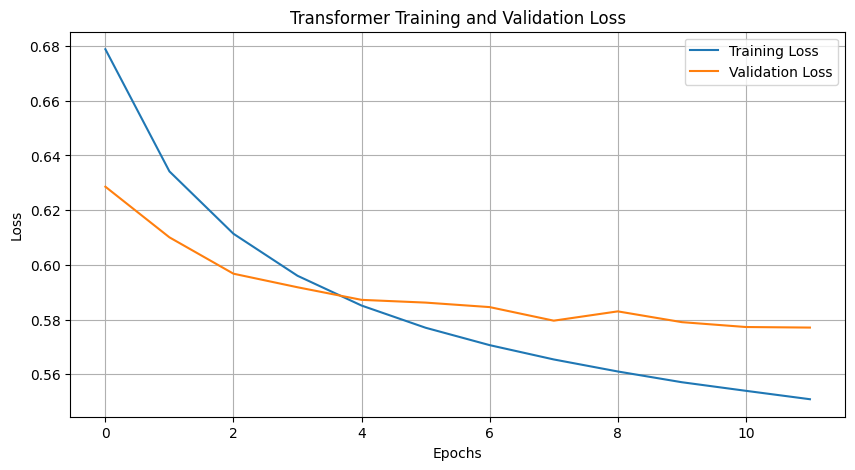

In [27]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Transformer Training and Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [28]:
test_loss, test_accuracy = transformer.evaluate(
    x=(
        test_encoder,
        test_decoder_input
    ),

    y=test_target,

    sample_weight=test_weights,

    batch_size=BATCH_SIZE
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

685/685 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.5625 - loss: 0.5775
Test Loss: 0.5774716734886169
Test Accuracy: 0.562541127204895


In [29]:
def translate_sentence(sentence):

    sentence = clean_text(sentence)

    # English tokenization
    sequence = english_tokenizer.texts_to_sequences(
        [sentence]
    )

    # Encoder padding
    encoder_input = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    encoder_input = tf.convert_to_tensor(
        encoder_input,
        dtype=tf.int32
    )

    # Begin Spanish sentence
    decoder_tokens = [START_TOKEN]

    for _ in range(MAX_LEN - 1):

        decoder_input = pad_sequences(
            [decoder_tokens],
            maxlen=MAX_LEN - 1,
            padding="post",
            truncating="post"
        )

        decoder_input = tf.convert_to_tensor(
            decoder_input,
            dtype=tf.int32
        )

        predictions = transformer(
            (encoder_input, decoder_input),
            training=False
        )

        # Prediction for the last generated position
        next_token_logits = predictions[
            0,
            len(decoder_tokens) - 1,
            :
        ]

        next_token = int(
            tf.argmax(next_token_logits).numpy()
        )

        # Stop when END or PAD is generated
        if next_token == END_TOKEN or next_token == PAD_TOKEN:
            break

        decoder_tokens.append(next_token)

    # Convert token IDs into Spanish words
    translated_words = []

    for token in decoder_tokens[1:]:

        word = spanish_tokenizer.index_word.get(
            token,
            "<UNK>"
        )

        translated_words.append(word)

    return " ".join(translated_words)

In [30]:
english_sentence = "I am a student."

spanish_translation = translate_sentence(
    english_sentence
)

print("English:", english_sentence)
print("Spanish:", spanish_translation)

English: I am a student.
Spanish: soy estudiante.


In [31]:
test_sentences = [
    "How are you?",
    "I love learning new things.",
    "What is your name?",
    "Good morning.",
    "I am going to school."
]

for sentence in test_sentences:

    translation = translate_sentence(sentence)

    print("\nEnglish:", sentence)
    print("Spanish:", translation)
    print("-" * 50)


English: How are you?
Spanish: ¿cómo estás?
--------------------------------------------------

English: I love learning new things.
Spanish: amo las nuevas cosas.
--------------------------------------------------

English: What is your name?
Spanish: ¿cuál es tu nombre?
--------------------------------------------------

English: Good morning.
Spanish: buenos días.
--------------------------------------------------

English: I am going to school.
Spanish: voy a la escuela.
--------------------------------------------------


In [32]:
predictions = []
references = []

NUM_BLEU_SAMPLES = min(500, len(test_df))

for i in range(NUM_BLEU_SAMPLES):

    english_sentence = test_df.iloc[i]["English"]

    actual_spanish = test_df.iloc[i]["Spanish"]

    predicted_spanish = translate_sentence(
        english_sentence
    )

    predictions.append(predicted_spanish)
    references.append(actual_spanish)

    if (i + 1) % 50 == 0:
        print("Processed:", i + 1)

print("\nBLEU evaluation data prepared!")
print("Total predictions:", len(predictions))
print("Total references:", len(references))

Processed: 50
Processed: 100
Processed: 150
Processed: 200
Processed: 250
Processed: 300
Processed: 350
Processed: 400
Processed: 450
Processed: 500

BLEU evaluation data prepared!
Total predictions: 500
Total references: 500


In [33]:
bleu = sacrebleu.corpus_bleu(
    predictions,
    [references]
)

print("BLEU Score:", bleu.score)

BLEU Score: 13.108625797301231


In [36]:
sentence = input("Enter an English sentence: ")

translation = translate_sentence(sentence)

print("\nEnglish:", sentence)
print("Spanish:", translation)

Enter an English sentence: i am at home

English: i am at home
Spanish: estoy en casa
